# 11 - Results comparison

Reads every `results/*.json` written by notebooks 02-10. Nothing is hardcoded.

In [1]:
import glob, json
import pandas as pd
import matplotlib.pyplot as plt

rows = [json.load(open(p)) for p in sorted(glob.glob("../results/*.json"))]
df = pd.DataFrame(rows).drop(columns=["confusion_matrix"])
cols = ["model", "sensor", "accuracy", "precision_botnet", "recall_botnet", "f1_botnet", "f1_macro"]
df[cols].sort_values(["sensor", "model"]).round(4)

,model,sensor,accuracy,precision_botnet,recall_botnet,f1_botnet,f1_macro
0,FT-Transformer,sensor1,0.9968,0.9638,0.9279,0.9455,0.9719
2,SAINT,sensor1,0.9360,0.3115,0.9467,0.4688,0.7174
5,TabTransformer,sensor1,0.9962,0.9436,0.9291,0.9363,0.9672
1,FT-Transformer,sensor2,0.9924,0.9495,0.9241,0.9366,0.9663
3,SAINT,sensor2,0.9388,0.4977,0.9197,0.6458,0.8062
6,TabTransformer,sensor2,0.9899,0.9352,0.8954,0.9149,0.9547
4,SAINT,sensor3,0.9292,0.5176,0.9500,0.6701,0.8152
7,TabTransformer,sensor3,0.9866,0.9245,0.8967,0.9104,0.9516


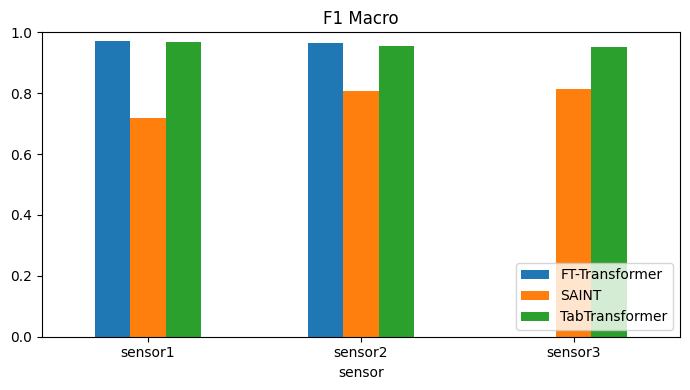

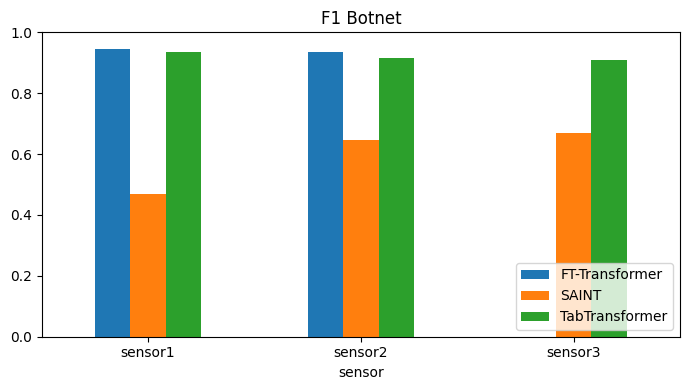

In [2]:
for metric in ["f1_macro", "f1_botnet"]:
    pivot = df.pivot(index="sensor", columns="model", values=metric)
    ax = pivot.plot(kind="bar", figsize=(7, 4), rot=0)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylim(0, 1)
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

In [3]:
# Markdown table for the README
print(df[cols].sort_values(["sensor", "model"]).round(4).to_markdown(index=False))

| model          | sensor   |   accuracy |   precision_botnet |   recall_botnet |   f1_botnet |   f1_macro |
|:---------------|:---------|-----------:|-------------------:|----------------:|------------:|-----------:|
| FT-Transformer | sensor1  |     0.9968 |             0.9638 |          0.9279 |      0.9455 |     0.9719 |
| SAINT          | sensor1  |     0.936  |             0.3115 |          0.9467 |      0.4688 |     0.7174 |
| TabTransformer | sensor1  |     0.9962 |             0.9436 |          0.9291 |      0.9363 |     0.9672 |
| FT-Transformer | sensor2  |     0.9924 |             0.9495 |          0.9241 |      0.9366 |     0.9663 |
| SAINT          | sensor2  |     0.9388 |             0.4977 |          0.9197 |      0.6458 |     0.8062 |
| TabTransformer | sensor2  |     0.9899 |             0.9352 |          0.8954 |      0.9149 |     0.9547 |
| SAINT          | sensor3  |     0.9292 |             0.5176 |          0.95   |      0.6701 |     0.8152 |
| TabTransformer | 